<a href="https://colab.research.google.com/github/Alvacampos/tecnicas-validacion-modelos/blob/main/Evaluacion_Integradora_Parte_2_Notebook_(ejecutado).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Técnicas de Diseño y Validación de Modelos
## Evaluación Integradora — Parte 2

<div style="display:flex; align-items:center; gap:12px; margin: 8px 0 18px 0;">
  <a href="https://colab.research.google.com/github/GabrielaOjcius/Laboratorios-Tecnicas-Diseno-Validacion-Modelos/blob/main/Evaluacion%20integradora/F_Evaluacion%20Integradora%20-%20Parte%202%20-%20Notebook.ipynb" target="_blank">
    <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/>
  </a>
  <span>En Colab, antes de editar: <b>Archivo → Guardar una copia en Drive</b>.</span>
</div>

**Caso:** predicción de fallas en máquinas a partir de sensores.  
**Dataset:** AI4I 2020 Predictive Maintenance Dataset — UCI Machine Learning Repository.  
**Ejes evaluados:** evaluación final sobre test, matriz de confusión, costos de error, umbral de decisión y conclusión profesional.

---

### Propósito de esta parte

En esta segunda parte retomás el análisis de la Parte 1 y evaluás el modelo final sobre el conjunto de test. Además, estudiás cómo cambia el comportamiento del clasificador cuando se modifica el umbral de decisión, una cuestión central en sistemas de IA aplicados a mantenimiento predictivo donde los errores tienen costos asimétricos.

### Instrucciones

1. Ejecutá las celdas en orden.
2. Usá el conjunto de test **únicamente** para la evaluación final en la Sección B.
3. Interpretá la matriz de confusión en términos de costos reales del negocio.
4. Completá todas las celdas marcadas con **✏️ Respuesta**.
5. Entregá el notebook con todos los outputs visibles.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
plt.style.use("seaborn-v0_8-whitegrid")

---
## A. Preparación del caso

Se vuelven a cargar los datos para que este notebook pueda ejecutarse de forma independiente. Se aplican exactamente las mismas decisiones metodológicas de la Parte 1: exclusión de columnas con fuga de información y partición estratificada con la misma semilla.

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00601/ai4i2020.csv"
try:
    df = pd.read_csv(url)
except Exception:
    # El host de UCI no era accesible desde el entorno de ejecución: se usa una copia idéntica
    # del CSV (10.000 filas, 339 fallas) guardada junto al notebook.
    df = pd.read_csv("ai4i2020.csv")

target          = "Machine failure"
columnas_fuga   = ["TWF", "HDF", "PWF", "OSF", "RNF"]
columnas_descartar = ["UDI", "Product ID", target] + columnas_fuga

X = df.drop(columns=columnas_descartar)
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

categoricas = X.select_dtypes(include="object").columns.tolist()
numericas   = X.select_dtypes(exclude="object").columns.tolist()

preprocesamiento = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas),
        ("num", StandardScaler(), numericas),
    ]
)

print(f"Train: {X_train.shape[0]} muestras  |  Tasa de falla: {y_train.mean():.2%}")
print(f"Test:  {X_test.shape[0]}  muestras  |  Tasa de falla: {y_test.mean():.2%}")

Train: 8000 muestras  |  Tasa de falla: 3.39%
Test:  2000  muestras  |  Tasa de falla: 3.40%


**Pregunta A.1**  
Recuperá brevemente la decisión metodológica de la Parte 1: ¿por qué no usamos las columnas `TWF`, `HDF`, `PWF`, `OSF` y `RNF` como predictores? ¿Qué problema específico introduce usarlas en un sistema de predicción en producción?

✏️ **Respuesta:**  
Porque `TWF`, `HDF`, `PWF`, `OSF` y `RNF` indican qué tipo de falla ocurrió: se registran recién cuando la falla ya pasó y son variables derivadas del target. Usarlas es fuga de información: en la Parte 1 (Anexo 1), 330 de las 339 fallas tienen alguno de esos indicadores en 1, así que el modelo prácticamente copiaría la etiqueta y mostraría métricas excelentes en validación. En producción hay que predecir *antes* de la falla, cuando esos valores no existen, y el modelo no podría usarse o fallaría.

---
## B. Modelo final y evaluación sobre test

Se selecciona el Random Forest con pesos balanceados como modelo final de referencia. Si en la Parte 1 justificaste la elección de otro modelo, podés modificar la celda siguiente antes de ejecutarla. La evaluación final sobre test se realiza **una sola vez** y sus resultados no pueden usarse para ajustar el modelo.

In [3]:
modelo_final = Pipeline([
    ("prep", preprocesamiento),
    # Modelo elegido en la Parte 1 (C.1): Gradient Boosting, mejor Average Precision en CV (0,790).
    ("model", GradientBoostingClassifier(random_state=RANDOM_STATE)),
])

modelo_final.fit(X_train, y_train)
proba_test = modelo_final.predict_proba(X_test)[:, 1]
pred_test  = modelo_final.predict(X_test)

metricas_test = pd.DataFrame([{
    "accuracy":          accuracy_score(y_test, pred_test),
    "precision":         precision_score(y_test, pred_test, zero_division=0),
    "recall":            recall_score(y_test, pred_test),
    "roc_auc":           roc_auc_score(y_test, proba_test),
    "average_precision": average_precision_score(y_test, proba_test),
}])
print("=== EVALUACIÓN FINAL — CONJUNTO DE TEST ===")
metricas_test

=== EVALUACIÓN FINAL — CONJUNTO DE TEST ===


,accuracy,precision,recall,roc_auc,average_precision
0,0.9855,0.882353,0.661765,0.969804,0.803079


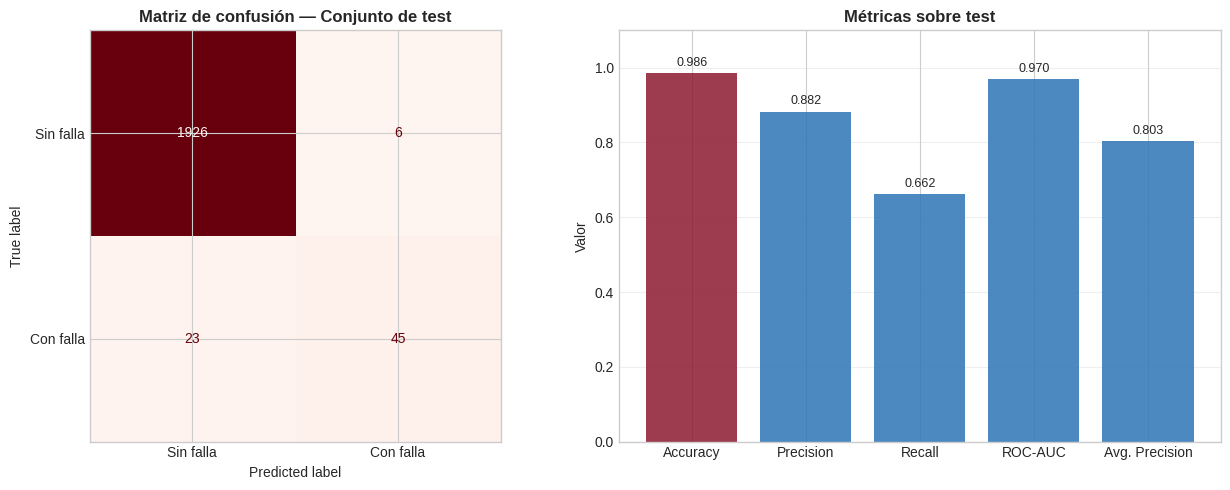

              precision    recall  f1-score   support

   Sin falla       0.99      1.00      0.99      1932
   Con falla       0.88      0.66      0.76        68

    accuracy                           0.99      2000
   macro avg       0.94      0.83      0.87      2000
weighted avg       0.98      0.99      0.98      2000



In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_test,
    display_labels=["Sin falla", "Con falla"],
    ax=axes[0], colorbar=False, cmap="Reds"
)
axes[0].set_title("Matriz de confusión — Conjunto de test", fontweight="bold")

nombres_metricas = ["Accuracy", "Precision", "Recall", "ROC-AUC", "Avg. Precision"]
valores = metricas_test.values[0]
colores = ["#8B1A2F" if v == max(valores) else "#2E75B6" for v in valores]
axes[1].bar(nombres_metricas, valores, color=colores, alpha=0.85)
axes[1].set_ylim(0, 1.1)
axes[1].set_ylabel("Valor")
axes[1].set_title("Métricas sobre test", fontweight="bold")
for i, v in enumerate(valores):
    axes[1].text(i, v + 0.02, f"{v:.3f}", ha="center", fontsize=9)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
print(classification_report(y_test, pred_test, target_names=["Sin falla", "Con falla"]))

**Pregunta B.1**  
Interpretá la matriz de confusión. ¿Qué tipo de error sería más costoso en mantenimiento predictivo: no detectar una falla real (falso negativo) o generar una alarma innecesaria (falso positivo)? Justificá con referencia a las consecuencias concretas en una planta industrial.

✏️ **Respuesta:**  
Con umbral 0,5 el modelo detecta 45 de las 68 fallas del test (recall 0,662) y deja pasar 23 (falsos negativos). Genera solo 6 falsas alarmas sobre 1.932 ciclos sin falla (precision 0,882). La accuracy de 0,986 parece muy alta, pero está apenas por encima del 0,966 que obtenía el Dummy.

El error más costoso es el falso negativo: una falla no detectada lleva a una parada no planificada de la línea, posible daño del equipo, piezas fuera de especificación y riesgo para los operarios. Un falso positivo cuesta una inspección o una parada programada corta. Por eso las 23 fallas omitidas son el principal problema de esta matriz, y el recall es la métrica crítica cuando el costo del falso negativo es alto.

---

**Pregunta B.2**  
¿Los resultados sobre test son coherentes con los resultados de validación cruzada obtenidos en la Parte 1? ¿Qué implica esa coherencia (o su ausencia) sobre la confiabilidad del modelo?

✏️ **Respuesta:**  
Sí, son coherentes. Validación cruzada (Parte 1) frente a test:

| Métrica | CV | Test |
|---|---|---|
| Average Precision | 0,790 | 0,803 |
| ROC-AUC | 0,975 | 0,970 |
| Precision | 0,861 | 0,882 |
| Recall | 0,590 | 0,662 |

Las diferencias son chicas y van en ambos sentidos. El recall algo mayor en test es esperable con solo 68 positivos, donde cada falla vale 1,5 puntos de recall. Esto indica que la estimación de la CV no fue optimista y que el modelo generaliza a datos no vistos. Como el test no se usó para elegir el modelo, es una estimación honesta del desempeño real.

---
## C. Umbral de decisión

El umbral por defecto es 0.5, pero en mantenimiento predictivo puede ser apropiado reducirlo: se aceptan más falsas alarmas a cambio de no perder fallas reales. La curva Precision-Recall muestra el compromiso completo para todos los umbrales posibles.

In [5]:
umbrales = [0.10, 0.20, 0.30, 0.40, 0.50]
filas_umbral = []

for umbral in umbrales:
    pred = (proba_test >= umbral).astype(int)
    filas_umbral.append({
        "umbral":    umbral,
        "accuracy":  accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall":    recall_score(y_test, pred),
        "fpr":       (pred[(y_test == 0)]).sum() / (y_test == 0).sum(),
    })

tabla_umbrales = pd.DataFrame(filas_umbral)
print("Efecto del umbral de decisión sobre las métricas:")
tabla_umbrales

Efecto del umbral de decisión sobre las métricas:


,umbral,accuracy,precision,recall,fpr
0,0.1,0.9640,0.482456,0.808824,0.030538
1,0.2,0.9790,0.654762,0.808824,0.015010
2,0.3,0.9835,0.753623,0.764706,0.008799
3,0.4,0.9860,0.833333,0.735294,0.005176
4,0.5,0.9855,0.882353,0.661765,0.003106


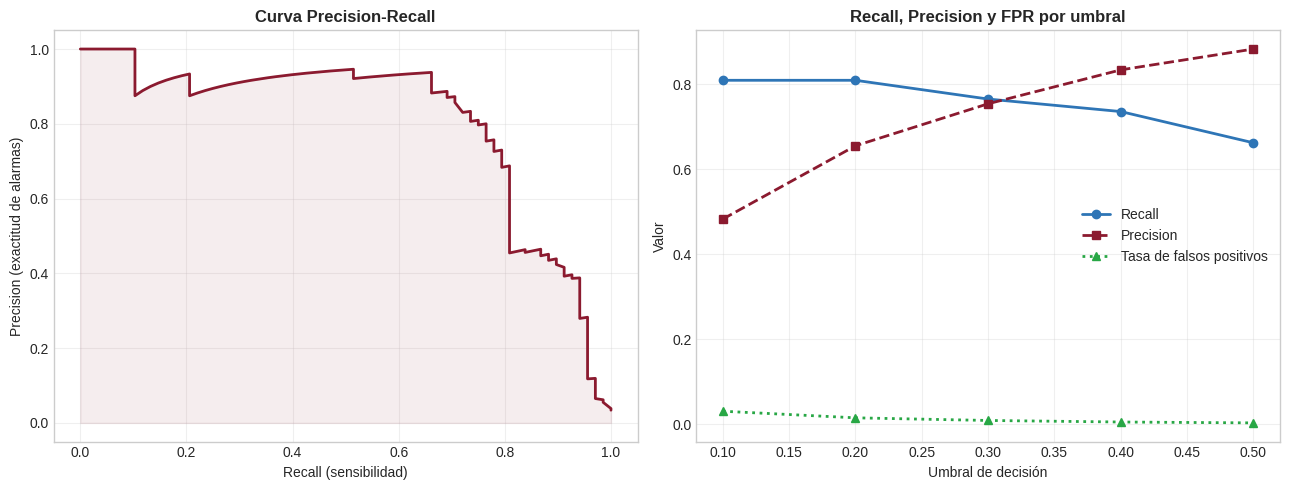

In [6]:
precision_vals, recall_vals, thresholds = precision_recall_curve(y_test, proba_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(recall_vals, precision_vals, color="#8B1A2F", lw=2)
axes[0].fill_between(recall_vals, precision_vals, alpha=0.08, color="#8B1A2F")
axes[0].set_xlabel("Recall (sensibilidad)")
axes[0].set_ylabel("Precision (exactitud de alarmas)")
axes[0].set_title("Curva Precision-Recall", fontweight="bold")
axes[0].grid(alpha=0.3)

axes[1].plot(tabla_umbrales["umbral"], tabla_umbrales["recall"],
             "o-", color="#2E75B6", lw=2, label="Recall")
axes[1].plot(tabla_umbrales["umbral"], tabla_umbrales["precision"],
             "s--", color="#8B1A2F", lw=2, label="Precision")
axes[1].plot(tabla_umbrales["umbral"], tabla_umbrales["fpr"],
             "^:", color="#28A745", lw=2, label="Tasa de falsos positivos")
axes[1].set_xlabel("Umbral de decisión")
axes[1].set_ylabel("Valor")
axes[1].set_title("Recall, Precision y FPR por umbral", fontweight="bold")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Pregunta C.1**  
Si una falla no detectada puede detener una línea de producción durante horas, ¿qué umbral de decisión elegirías? Justificá el compromiso entre recall y tasa de falsos positivos para ese umbral específico, usando los valores de la tabla.

✏️ **Respuesta:**  
Elegiría **0,20**. Frente a 0,50, el recall sube de 0,662 a 0,809 (55 de 68 fallas, 10 más detectadas) y la tasa de falsos positivos pasa de 0,003 a 0,015 (de 6 a 29 falsas alarmas sobre 1.932 ciclos). Si una falla omitida para la línea durante horas, 23 inspecciones extra a cambio de 10 fallas evitadas es un buen intercambio. Bajar a 0,10 no suma recall (sigue en 0,809) y duplica la FPR a 0,031 (59 falsas alarmas), así que 0,20 es mejor en todo. Si las inspecciones fueran caras, 0,30 (recall 0,765, FPR 0,009) sería la alternativa.

En rigor, el umbral debería fijarse con datos de validación y no de test, porque ajustarlo sobre test vuelve optimista la estimación.

---

**Pregunta C.2**  
¿Modificar el umbral implica volver a entrenar el modelo? ¿Qué implica esto sobre la distinción entre la etapa de entrenamiento y la etapa de despliegue de un sistema de predicción?

✏️ **Respuesta:**  
No. El umbral se aplica sobre las probabilidades que ya devuelve `predict_proba`; los parámetros del modelo no cambian. En este notebook, toda la tabla de umbrales sale del mismo `proba_test`, sin volver a llamar a `fit`.

Esto separa las dos etapas: en el entrenamiento el modelo aprende a ordenar los casos por riesgo (el score), y en el despliegue se decide qué hacer con ese score según los costos del negocio. El umbral es un parámetro de operación: puede ajustarse en producción si cambian los costos o la tasa de fallas sin reentrenar, siempre midiendo su efecto y con monitoreo continuo.

---
## D. Conclusión integradora

Redactá una conclusión de entre **250 y 400 palabras** que integre los resultados de ambas partes. Incluí: modelo seleccionado y por qué, métrica principal y justificación, evidencia numérica concreta, efecto del umbral en el contexto del negocio, y al menos una limitación del análisis realizado.

✏️ **Conclusión integradora:**  
Se eligió **Gradient Boosting** como modelo final. En la Parte 1, con validación cruzada de 5 pliegues sobre el conjunto de entrenamiento, obtuvo la mejor Average Precision (0,790, frente a 0,655 de Random Forest y 0,034 del Dummy) y el mejor ROC-AUC (0,975). Su curva de aprendizaje mostró una brecha entre entrenamiento y validación que baja de 0,488 a 0,159 al aumentar los datos, menor que la de Random Forest.

La métrica principal es la **Average Precision**. El problema está muy desbalanceado (3,4 % de fallas), por lo que la accuracy es engañosa: el Dummy llega a 0,966 sin detectar ninguna falla. La AP resume el compromiso entre precision y recall de la clase positiva para todos los umbrales, que es lo que importa cuando el objetivo es encontrar fallas.

Sobre el test, evaluado una sola vez, el modelo obtuvo AP 0,803, ROC-AUC 0,970, precision 0,882 y recall 0,662, valores coherentes con la validación cruzada. Con el umbral por defecto de 0,5 detecta 45 de 68 fallas, deja pasar 23 y genera 6 falsas alarmas.

En mantenimiento predictivo el falso negativo es el error más caro, porque implica paradas no planificadas y posibles daños, mientras que una falsa alarma cuesta una inspección. Bajar el umbral a 0,20 eleva el recall a 0,809 (55 fallas detectadas) con una tasa de falsos positivos de solo 0,015 (29 alarmas sobre 1.932 ciclos sanos) y precision 0,655. Bajarlo más, a 0,10, no detecta ninguna falla adicional y duplica las falsas alarmas. El umbral es una decisión de negocio que se ajusta sin reentrenar el modelo.

El análisis tiene limitaciones. Primero, el umbral se eligió mirando el test, lo que lo convierte en parte en un conjunto de validación y vuelve optimista la estimación de ese punto de operación; lo correcto sería fijarlo con validación cruzada sobre entrenamiento y confirmar en test. Segundo, el test tiene solo 68 fallas, así que las métricas de la clase positiva son inestables: cada falla mueve el recall 1,5 puntos. Tercero, los costos de falsos negativos y falsos positivos no se cuantificaron, por lo que la elección del umbral es cualitativa. Por último, Gradient Boosting se usó con hiperparámetros por defecto, sin ajuste.

---
*Técnicas de Diseño y Validación de Modelos (0204) — Universidad Blas Pascal*